Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

Objective: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?
Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [1]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

display(df.head())
print(df.columns.tolist())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


In [2]:
category_counts = df["category"].value_counts()
top_5 = category_counts.head(5)

display(top_5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

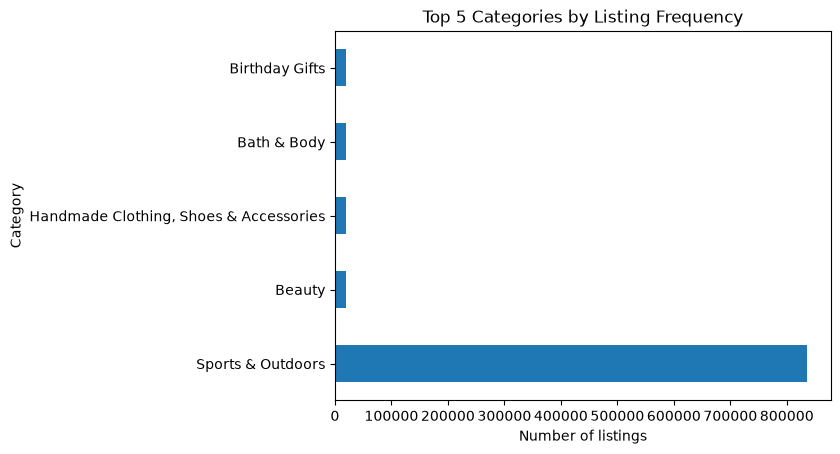

In [3]:
import matplotlib.pyplot as plt

top_5.plot(kind="barh")
plt.xlabel("Number of listings")
plt.ylabel("Category")
plt.title("Top 5 Categories by Listing Frequency")
plt.show()

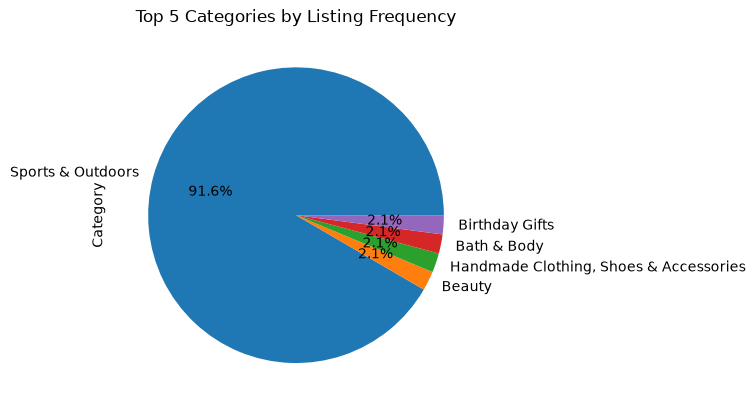

In [4]:
import matplotlib.pyplot as plt

top_5.plot(kind="pie", autopct="%1.1f%%")
plt.ylabel("Category")
plt.title("Top 5 Categories by Listing Frequency")
plt.show()

Sports & Outdoors dominates the top five categories, accounting for 91.6% of their combined listings. 
The other four categories have similar listing frequencies.

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?
Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?
Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [8]:
#mean, median, and mode for the price of products

mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]  # Assuming we want the first mode if there are multiple

print("Mean price:", mean_price)
print("Median price:", median_price)
print("Mode price:")
print(mode_price)

Mean price: 89.24380943923661
Median price: 19.09
Mode price:
9.99


In [ ]:
#variance, standard deviation, range, and interquartile range for product price

variance_price = df["price"].var()
std_price = df["price"].std()

range_price = df["price"].max() - df["price"].min()

q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr_price = q3 - q1

print("Variance:", variance_price)
print("Standard deviation:", std_price)
print("Range:", range_price)
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr_price)

Variance: 119445.48532254901
Standard deviation: 345.60886175349873
Range: 100000.0
Q1: 9.99
Q3: 45.99
IQR: 36.0


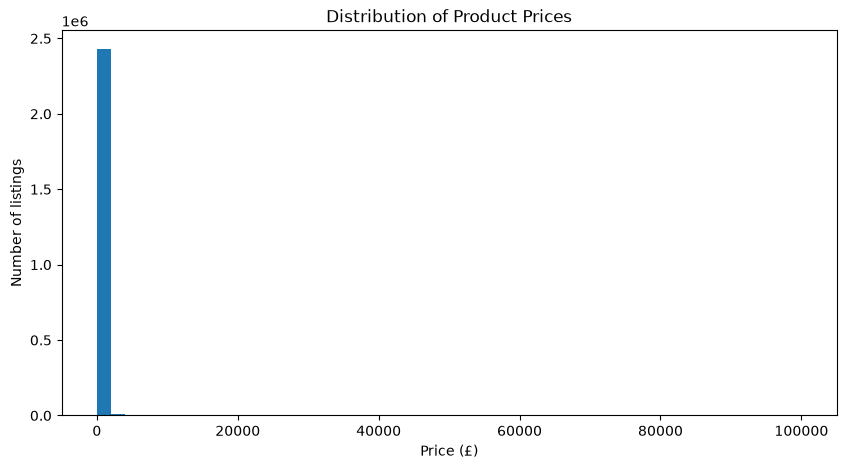

In [9]:
df["price"].plot(kind="hist", bins=50, figsize=(10, 5))
plt.xlabel("Price (£)")
plt.ylabel("Number of listings")
plt.title("Distribution of Product Prices")
plt.show()

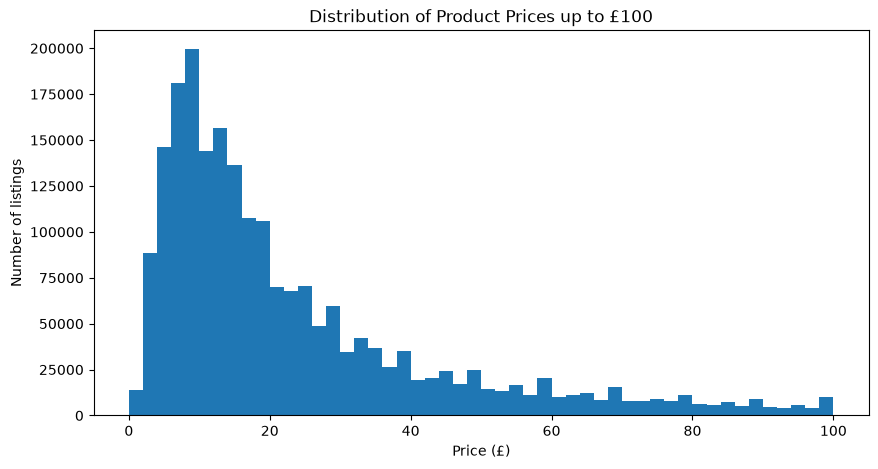

In [ ]:
#There is an outlier in the distribution of product prices, with a few products having very high prices compared to the majority of products. 
# This indicates that most products are priced relatively low, while a small number of products are priced significantly higher, creating a skewed distribution.
#Checking now the distribution of product prices up to £100, which is a more reasonable range for most products.
prices_under_100 = df.loc[df["price"] <= 100, "price"]

prices_under_100.plot(kind="hist", bins=50, figsize=(10, 5))
plt.xlabel("Price (£)")
plt.ylabel("Number of listings")
plt.title("Distribution of Product Prices up to £100")
plt.show()

In the histogram restricted to prices up to £100, the greatest concentration of listings appears between £5 and £20.

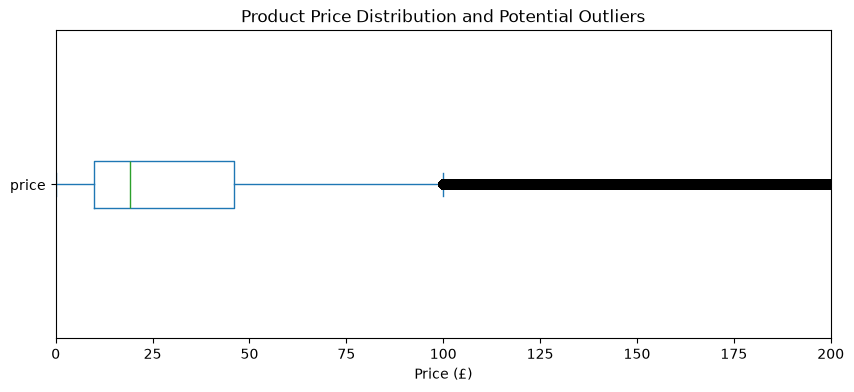

In [13]:
#box plot to showcase the spread and potential outliers in product pricing

df["price"].plot(kind="box", vert=False, figsize=(10, 4))
plt.xlabel("Price (£)")
plt.title("Product Price Distribution and Potential Outliers")
plt.xlim(0, 200)
plt.show()

The median (£19.09) better represents the typical product price because extremely high prices pull the mean (£89.24) upwards. The most common price is £9.99.

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1.Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

In [14]:
#Checking the values and frequency

display(df["stars"].value_counts().sort_index())

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

In [ ]:
#Checking the reviews column with reviews = 0.

display(df.loc[df["stars"] == 0, "reviews"].value_counts().head())

reviews
0    1225641
Name: count, dtype: int64

In [16]:
rated_products = df.loc[df["stars"] > 0, "stars"]

mean_rating = rated_products.mean()
median_rating = rated_products.median()
mode_rating = rated_products.mode()

print("Mean rating:", mean_rating)
print("Median rating:", median_rating)
print("Mode rating:")
print(mode_rating)

Mean rating: 4.319160762226911
Median rating: 4.4
Mode rating:
0    4.5
Name: stars, dtype: float64


In [17]:
variance_rating = rated_products.var()
std_rating = rated_products.std()

q1_rating = rated_products.quantile(0.25)
q3_rating = rated_products.quantile(0.75)
iqr_rating = q3_rating - q1_rating

print("Variance:", variance_rating)
print("Standard deviation:", std_rating)
print("Q1:", q1_rating)
print("Q3:", q3_rating)
print("IQR:", iqr_rating)

Variance: 0.3083433752387284
Standard deviation: 0.5552867504620729
Q1: 4.1
Q3: 4.6
IQR: 0.5


In [18]:
print("Skewness:", rated_products.skew())
print("Kurtosis:", rated_products.kurt())

Skewness: -2.379568112212799
Kurtosis: 9.78193769066435


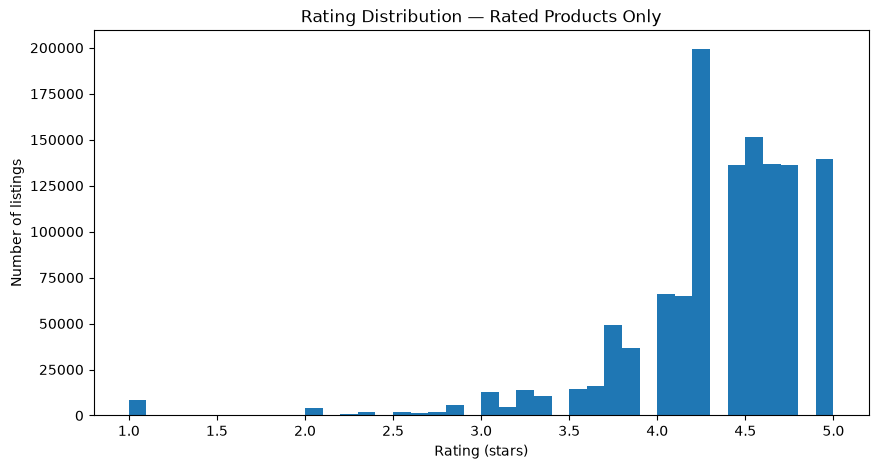

In [19]:
rated_products.plot(kind="hist", bins=40, figsize=(10, 5))
plt.xlabel("Rating (stars)")
plt.ylabel("Number of listings")
plt.title("Rating Distribution — Rated Products Only")
plt.show()

Only rated products were included.
Most ratings fall between 4 and 5 stars.
The distribution is negatively skewed.

# Business Report

## Overview

This analysis explores product categories, prices and ratings to support product positioning and pricing decisions. Listing frequency measures product availability in this dataset, not sales or customer demand.

## 1. Product Categories

| Top Category | Number of Listings |
|---|---:|
| Sports & Outdoors | 836,265 |
| Beauty | 19,312 |
| Handmade Clothing, Shoes & Accessories | 19,229 |
| Bath & Body | 19,092 |
| Birthday Gifts | 18,978 |

Sports & Outdoors accounts for **91.6% of the combined listings in the top five categories**. The remaining four categories have similar listing frequencies.

**Business insight:** The large assortment in Sports & Outdoors suggests substantial competition among listings. However, sales data and category validation are needed before concluding that it offers the strongest business opportunity.

## 2. Product Pricing

| Metric | Result |
|---|---:|
| Mean | £89.24 |
| Median | £19.09 |
| Mode | £9.99 |
| Variance | 119,445.49 £² |
| Standard deviation | £345.61 |
| Range | £100,000 |
| First quartile (Q1) | £9.99 |
| Third quartile (Q3) | £45.99 |
| Interquartile range | £36.00 |

The mean is considerably higher than the median, indicating that expensive products pull the average upwards. The middle 50% of prices fall between **£9.99 and £45.99**.

In the histogram restricted to prices up to £100, the greatest concentration appears between **£5 and £20**. Extreme values make the full histogram and box plot difficult to read; restricting the displayed range improves visibility.

Using the IQR criterion, prices above **£99.99** are potential outliers. These may represent legitimate expensive products or data issues and require investigation.

**Business insight:** The median is a better benchmark for typical pricing than the overall mean. Businesses should compare prices within relevant categories before setting prices.

## 3. Product Ratings

The ratings analysis excludes **1,225,641 products with zero stars and zero reviews**, treating these as unrated listings. The original dataset remains unchanged.

| Metric | Rated Products |
|---|---:|
| Mean | 4.32 stars |
| Median | 4.4 stars |
| Mode | 4.5 stars |
| Variance | 0.308 stars² |
| Standard deviation | 0.56 stars |
| First quartile (Q1) | 4.1 stars |
| Third quartile (Q3) | 4.6 stars |
| Interquartile range | 0.5 stars |
| Skewness | -2.38 |
| Excess kurtosis | 9.78 |

Ratings concentrate between **4 and 5 stars**, with the middle 50% between **4.1 and 4.6 stars**. Negative skewness indicates a tail towards lower ratings. The histogram and distribution statistics indicate a non-normal distribution.

**Business insight:** High ratings are common among rated products. Businesses should consider review counts alongside ratings and differentiate through product features, pricing and service.

## 4. Business Recommendations

- **Use category-specific benchmarks:** Overall prices combine very different product types.
- **Investigate unusual values:** Validate extreme prices and the large Sports & Outdoors category count.
- **Assess review strength:** Consider review volume alongside product ratings.
- **Monitor unrated products separately:** Zero stars with zero reviews should not be interpreted as negative feedback.
- **Validate demand before investing:** Combine listing data with sales, margins and inventory information.

## Conclusion

Typical prices are better represented by the **£19.09 median** than the £89.24 mean. Rated products generally receive high scores, while category listings are unevenly distributed. These findings provide useful benchmarks, but sales and profitability data are needed to guide investment and inventory decisions.